# HIV trends and treatment access

Dr. Aung Chit Moe, MBBS. UNAIDS 2026 and WDI stored snapshot. National ecological associations do not establish clinical or programme effects. Sources and complete methods: ../reports/research_report.md. Censored values remain missing numerically and retain source labels.

## Snapshot and lineage

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
sys.path.insert(0,str(ROOT/'src'))
from research_io import load_results
r=load_results()
d=pd.read_csv(ROOT/'data/processed/southeast_asia_hiv_longitudinal_1990_2025.csv')
print('Southeast Asia countries:',d.iso3.nunique(),'country-years:',len(d))

Southeast Asia countries: 11 country-years: 396


## Descriptive changes

In [2]:
display(pd.read_csv(ROOT/'reports/analysis_tables/regional_trend_summary_2010_2025.csv'))

,iso3,country_name,plhiv_2010,plhiv_2025,aids_deaths_2010,aids_deaths_2025,pct_change_deaths,new_infections_2010,new_infections_2025,pct_change_new_infections,art_coverage_2010,art_coverage_2025,art_gain_percentage_points
0,THA,Thailand,810000.0,620000.0,41000.0,8400.0,-79.5,21000.0,7300.0,-65.2,27.0,82.0,55.0
1,UNACAR,Caribbean,290000.0,340000.0,14000.0,4800.0,-65.7,19000.0,13000.0,-31.6,18.0,73.0,55.0
2,MMR,Myanmar,250000.0,310000.0,12000.0,4400.0,-63.3,17000.0,9500.0,-44.1,12.0,73.0,61.0
3,UNAESA,Eastern and southern Africa,16900000.0,21100000.0,630000.0,240000.0,-61.9,1100000.0,420000.0,-61.8,25.0,85.0,60.0
4,UNAWCA,Western and central Africa,5000000.0,5200000.0,280000.0,110000.0,-60.7,340000.0,190000.0,-44.1,17.0,74.0,57.0
5,UNAAP,Asia and the Pacific,6000000.0,7100000.0,300000.0,120000.0,-60.0,350000.0,280000.0,-20.0,15.0,72.0,57.0
6,03M49WLD,Global,32500000.0,41000000.0,1300000.0,570000.0,-56.2,2100000.0,1200000.0,-42.9,24.0,78.0,54.0
7,KHM,Cambodia,81000.0,76000.0,1700.0,1000.0,-41.2,2300.0,960.0,-58.3,50.0,95.0,45.0
8,MYS,Malaysia,73000.0,85000.0,3400.0,2000.0,-41.2,6100.0,2900.0,-52.5,18.0,63.0,45.0
9,UNALA,Latin America,1400000.0,2600000.0,46000.0,28000.0,-39.1,110000.0,140000.0,27.3,34.0,71.0,37.0


## Cascade denominators and censoring

In [3]:
c=pd.read_csv(ROOT/'reports/analysis_tables/cascade_2025_summary.csv')
display(c[c.is_southeast_asia.eq(1)][['country_name','diagnosed_1st95_pct_source','on_art_2nd95_pct_source','virally_suppressed_3rd95_pct_source','virally_suppressed_all_pct_source']])

,country_name,diagnosed_1st95_pct_source,on_art_2nd95_pct_source,virally_suppressed_3rd95_pct_source,virally_suppressed_all_pct_source
0,Brunei Darussalam,...,...,...,...
1,Indonesia,67,72,95,45
2,Cambodia,95,>98,>98,93
3,Lao PDR,75,86,97,63
4,Myanmar,84,86,96,70
5,Malaysia,66,95,88,55
6,Philippines,62,66,97,40
7,Singapore,...,...,...,...
8,Thailand,90,92,>98,81
9,Timor-Leste,89,74,70,46


## Exploratory model comparisons

In [4]:
display(pd.DataFrame(r['models'])[['model_name','coefficient','ci_lower_95','ci_upper_95','n_observations','n_countries']])
print(r['inference'])

,model_name,coefficient,ci_lower_95,ci_upper_95,n_observations,n_countries
0,Country FE: current ART,-0.040924,-0.064874,-0.016974,109,7
1,Country FE: lag 1,-0.039984,-0.061395,-0.018573,103,7
2,Country FE: lag 2,-0.037989,-0.057927,-0.018050,97,7
3,Country and year FE: lag 1,-0.103191,-0.137819,-0.068563,103,7
4,Country and year FE: lag 1 + GDP,-0.093390,-0.123908,-0.062873,103,7
5,Country FE: common GDP sample,-0.039984,-0.061395,-0.018573,103,7
6,Country and year FE: 2011-2019,-0.112310,-0.129189,-0.095431,61,7
7,Country and year FE: omit Myanmar,-0.122919,-0.184186,-0.061652,88,6
8,Population denominator: country/year FE,-0.590584,-1.204449,0.023281,103,7
9,First differences with country/year effects,-0.061472,-0.086589,-0.036356,96,7


Country-clustered standard errors, full dummy design rank correction, t reference with G-1 degrees of freedom. Few clusters make intervals approximate.


## Sensitivity and limitations

In [5]:
display(pd.DataFrame(r['leave_one_country_out'])[['model_name','coefficient','ci_lower_95','ci_upper_95','n_observations']])
for note in r['limitations']: print(note)

,model_name,coefficient,ci_lower_95,ci_upper_95,n_observations
0,Omit IDN,-0.096693,-0.137532,-0.055854,88
1,Omit KHM,-0.103697,-0.142135,-0.065259,88
2,Omit MMR,-0.122919,-0.184186,-0.061652,88
3,Omit MYS,-0.101931,-0.135240,-0.068623,88
4,Omit PHL,-0.103175,-0.144971,-0.061379,90
5,Omit THA,-0.095129,-0.114125,-0.076133,88
6,Omit VNM,-0.105294,-0.153686,-0.056902,88


UNAIDS mortality estimates incorporate ART inputs and assumed survival. Associations partly reflect model construction.
Both ART coverage and deaths/PLHIV use estimated PLHIV denominators. The ratio is not a cohort fatality risk.
Annual estimates are rounded and serially related. Regression intervals do not propagate UNAIDS estimation uncertainty.
Year effects remove shared annual shocks only. Residual confounding, reverse causality and country-specific trends remain.
Primary analysis excludes censored values. Boundary substitution is a sensitivity scenario, not an estimate of missing values.


## SQLite reconciliation and figure

,year,plhiv,aids_deaths,art_coverage_pct
0,2010,250000.0,12000.0,12.0
1,2011,250000.0,11000.0,16.0
2,2012,250000.0,11000.0,21.0
3,2013,260000.0,9700.0,26.0
4,2014,260000.0,8800.0,33.0
5,2015,270000.0,7800.0,40.0
6,2016,270000.0,6900.0,47.0
7,2017,270000.0,6100.0,53.0
8,2018,280000.0,5400.0,60.0
9,2019,280000.0,4800.0,65.0


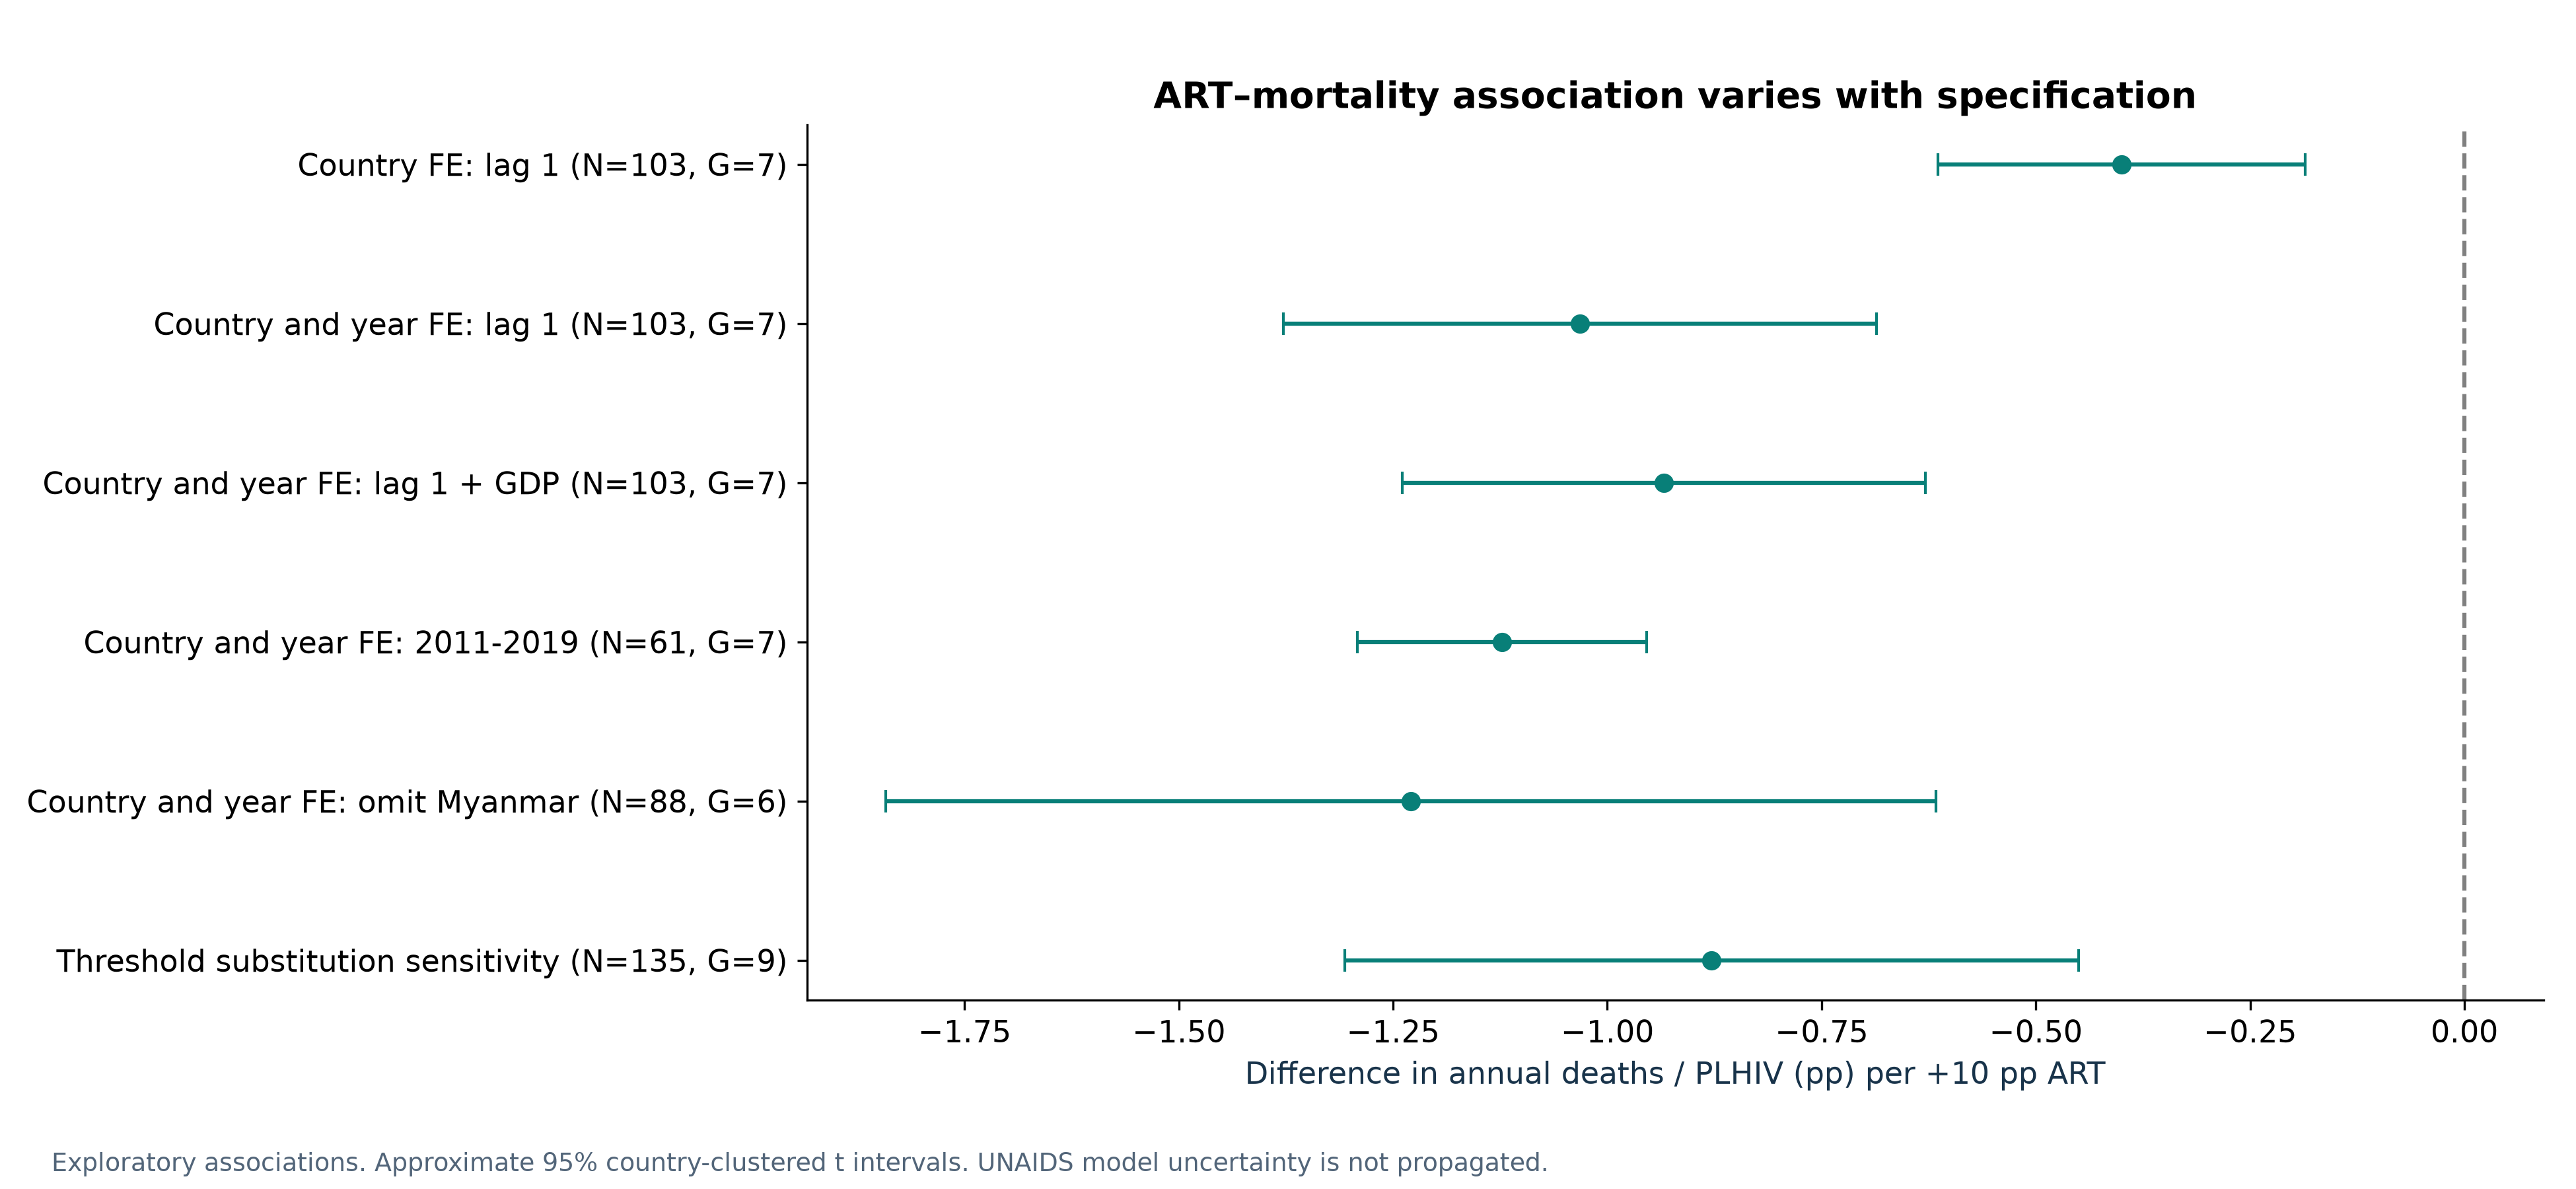

In [6]:
import sqlite3
with sqlite3.connect((ROOT/'data/processed/hiv_surveillance.db').as_uri()+'?mode=ro',uri=True) as con:
    display(pd.read_sql_query("select year,plhiv,aids_deaths,art_coverage_pct from v_southeast_asia_surveillance where iso3='MMR' and year>=2010",con))
display(Image(filename=str(ROOT/'figures/fig4_lagged_art_mortality_associations.png'),width=1000))